In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

In [61]:
data = load_breast_cancer()

In [41]:
print(data.feature_names)
print(data.target_names)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
['malignant' 'benign']


In [42]:
data.data.shape

(569, 30)

In [44]:
df = pd.DataFrame(
    data.data,
    columns = data.feature_names
)

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [46]:
df["target"] = data.target

In [52]:
df[df["target"] == 0]

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
563,20.92,25.09,143.00,1347.0,0.10990,0.22360,0.31740,0.14740,0.2149,0.06879,...,29.41,179.10,1819.0,0.1407,0.4186,0.6599,0.2542,0.2929,0.09873,0
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.1410,0.2113,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.1166,0.1922,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.1139,0.3094,0.3403,0.1418,0.2218,0.07820,0


In [53]:
df[df["target"] == 1]

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
19,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,0.05766,...,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,1
20,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,0.06811,...,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,1
21,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,0.06905,...,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,1
37,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,0.05863,...,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,1
46,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,0.06503,...,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
558,14.590,22.68,96.39,657.1,0.08473,0.13300,0.10290,0.037360,0.1454,0.06147,...,27.27,105.90,733.5,0.10260,0.31710,0.36620,0.11050,0.2258,0.08004,1
559,11.510,23.93,74.52,403.5,0.09261,0.10210,0.11120,0.041050,0.1388,0.06570,...,37.16,82.28,474.2,0.12980,0.25170,0.36300,0.09653,0.2112,0.08732,1
560,14.050,27.15,91.38,600.4,0.09929,0.11260,0.04462,0.043040,0.1537,0.06171,...,33.17,100.20,706.7,0.12410,0.22640,0.13260,0.10480,0.2250,0.08321,1
561,11.200,29.37,70.67,386.0,0.07449,0.03558,0.00000,0.000000,0.1060,0.05502,...,38.30,75.19,439.6,0.09267,0.05494,0.00000,0.00000,0.1566,0.05905,1


In [55]:
df["target"].value_counts()

target
1    357
0    212
Name: count, dtype: int64

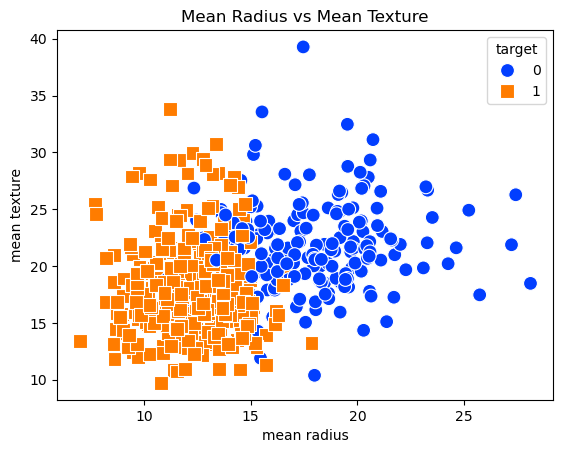

In [62]:
sns.scatterplot(
    data = df,
    x = "mean radius",
    y = "mean texture",
    hue = "target",
    style = "target",
    palette = "bright",
    markers = ["o","s","^"],
    s = 100
)
plt.title("Mean Radius vs Mean Texture")
plt.show()

In [63]:
X = df.drop("target", axis = 1)
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [64]:
y = df["target"]
y.head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [67]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

In [68]:
print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

(455, 30)
(455,)
(114, 30)
(114,)


In [70]:
scaler = StandardScaler()
scaler

,copy,True
,with_mean,True
,with_std,True


In [72]:
X_train_scaled = scaler.fit_transform(X_train)
scaler

,copy,True
,with_mean,True
,with_std,True


In [76]:
knn = KNeighborsClassifier(n_neighbors = 3)
knn

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [77]:
knn.fit(X_train_scaled,y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [79]:
X_test_scaled = scaler.transform(X_test)

In [81]:
y_pred = knn.predict(X_test_scaled)
y_pred

array([0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1])

In [86]:
comparision = pd.DataFrame({
    "Actual Values" : y_test.values,
    "Predicted Values" : y_pred
})

comparision

,Actual Values,Predicted Values
0,0,0
1,1,1
2,0,0
3,1,1
4,0,0
...,...,...
109,0,0
110,1,1
111,0,0
112,1,1


In [93]:
new_data = [[	13.080,	15.71,	85.63,	520.0,	0.10750,	0.12700,	0.04568,	0.031100, 0.1967,	0.06811, 
              20.49,	96.09,	630.5,	0.13120,	0.27760,	0.18900,	0.07283,	0.3184,	0.08183,
             13.080,	15.71,	85.63,	520.0,	0.10750,	0.12700,	0.04568,	0.031100, 0.1967,	0.06811, 0.45677]]

In [94]:
new_data_scaled = scaler.transform(new_point)

In [98]:
pred = knn.predict(new_data_scaled)
print(pred[0])
data.target_names[pred[0]]

1


np.str_('benign')

In [99]:
from sklearn.metrics import accuracy_score

In [100]:
accuracy = accuracy_score(y_test,y_pred)
accuracy

0.9824561403508771

In [101]:
### Confusion Matrix

print(len(y_test))
print(len(y_pred))

114
114


In [102]:
from sklearn.metrics import confusion_matrix

In [103]:
cm = confusion_matrix(y_test,y_pred)
cm

array([[40,  2],
       [ 0, 72]])

In [104]:
classes = ['malignant' ,'benign']
cm_df = pd.DataFrame(
    cm, 
    index = [f"Actual {c}" for c in classes],
    columns = [f"Predicted {c}" for c in classes],
)

print("Confusion Matrix:")
print(cm_df)

Confusion Matrix:
                  Predicted malignant  Predicted benign
Actual malignant                   40                 2
Actual benign                       0                72


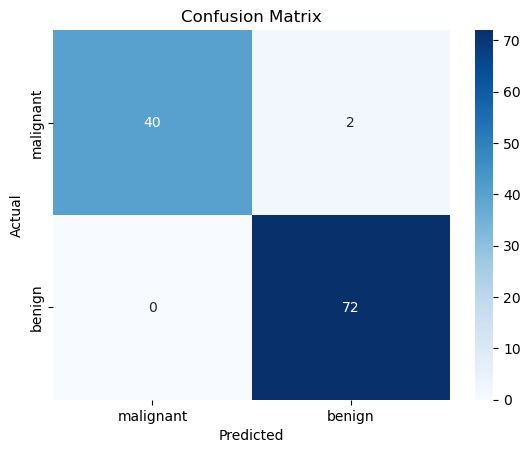

In [105]:
sns.heatmap(
    cm,
    annot = True,  # displays numerical values inside each cell
    fmt = 'd',  # displays as integers instead of decimals formatting
    cmap = 'Blues',  
    xticklabels = data.target_names,
    yticklabels = data.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [106]:
from sklearn.metrics import precision_score, recall_score

In [109]:
precision = precision_score(y_test,y_pred, average = None)
recall = recall_score(y_test,y_pred, average = None)

print("Precision:",precision)
print("Recall:",recall)

Precision: [1.         0.97297297]
Recall: [0.95238095 1.        ]


In [110]:
from sklearn.metrics import f1_score

In [112]:
f1 =  f1_score(y_test, y_pred, average = None)
print(f1)
print(f1 * 100)

[0.97560976 0.98630137]
[97.56097561 98.63013699]


In [113]:
from sklearn.metrics import roc_auc_score

In [122]:
y_proba = knn.predict_proba(X_test_scaled)[:,1]

In [123]:
roc_auc = roc_auc_score(
    y_test,
    y_proba,
    average = None
)

print("'ROC - AUC", roc_auc)

'ROC - AUC 0.9834656084656085


In [125]:
knn_minkowski = KNeighborsClassifier(
    n_neighbors = 3,
    metric = 'minkowski',
    p = 2
)

knn_minkowski.fit(X_train, y_train)
y_pred = knn_minkowski.predict(X_test)
print(accuracy_score(y_test,y_pred))

0.9298245614035088


In [126]:
knn_manhattan = KNeighborsClassifier(
    n_neighbors = 3,
    metric = 'manhattan',
)

knn_manhattan.fit(X_train, y_train)
y_pred = knn_manhattan.predict(X_test)
print(accuracy_score(y_test,y_pred))

0.9385964912280702


In [127]:
knn_hamming = KNeighborsClassifier(
    n_neighbors = 3,
    metric = 'hamming',
)

knn_hamming.fit(X_train, y_train)
y_pred = knn_hamming.predict(X_test)
print(accuracy_score(y_test,y_pred))

0.6929824561403509


In [128]:
knn_chebyshev = KNeighborsClassifier(
    n_neighbors = 3,
    metric = 'chebyshev',
)

knn_chebyshev.fit(X_train, y_train)
y_pred = knn_chebyshev.predict(X_test)
print(accuracy_score(y_test,y_pred))

0.9122807017543859
